
=========================== Loading Titanic Dataset ============================

Dataset loaded successfully. Shape: (891, 12)
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  

================== Exercise 1: Data Scaling and Normalization ==================

Numerical columns selected: ['Age', 'Fare']
Standardized Age (head):
 0   -0.565736
1    0.663861
2   -0.258337
Name: Age_

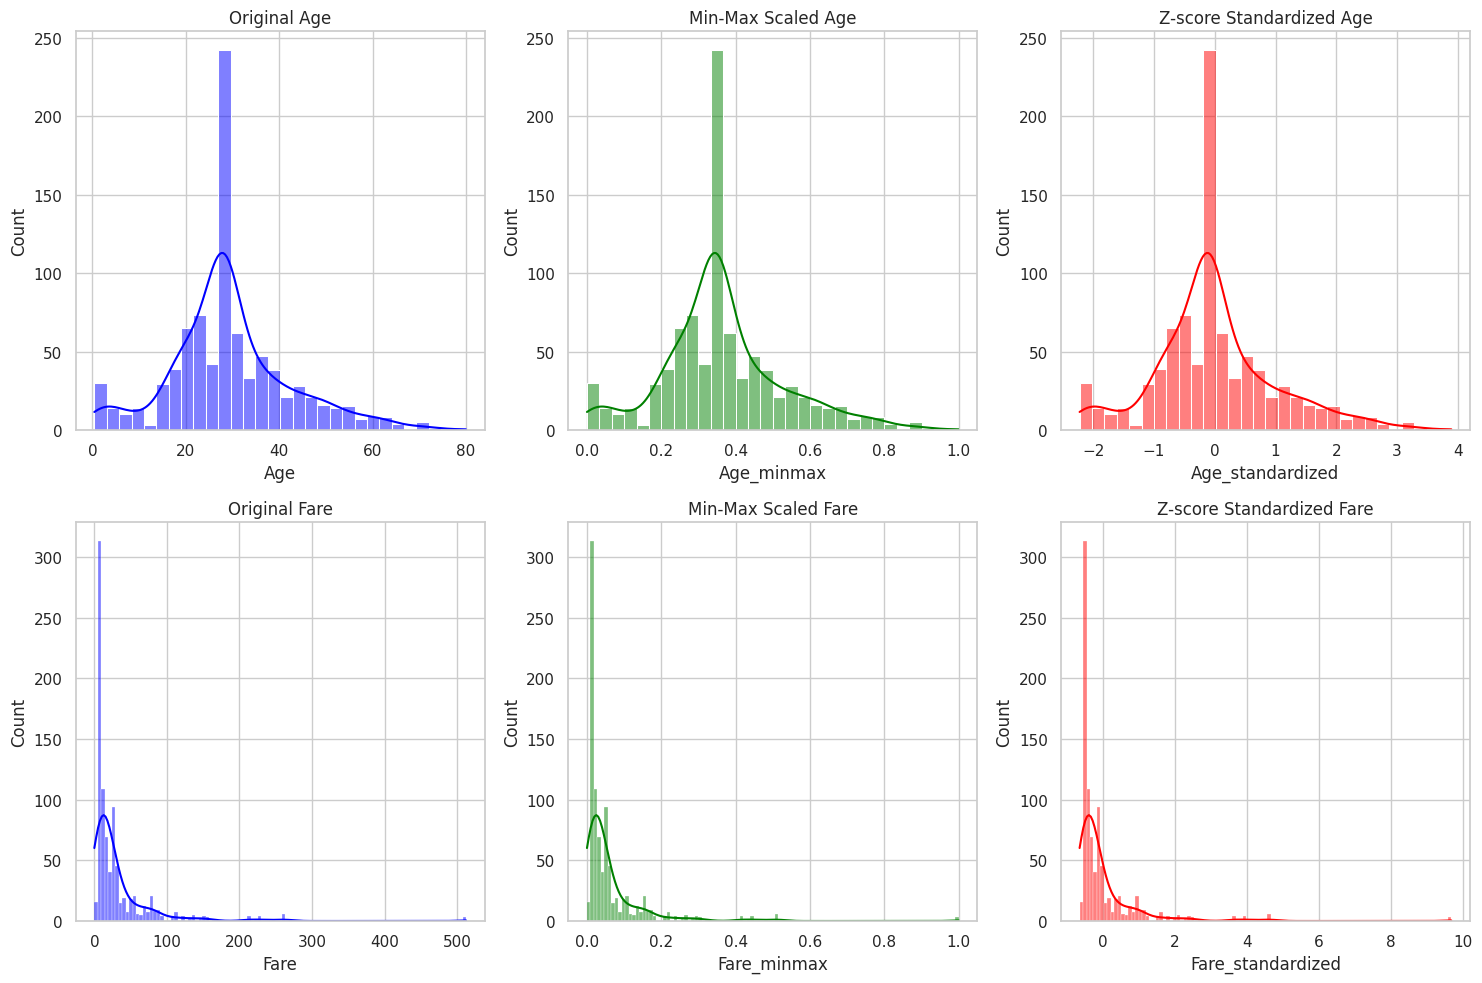


================== Exercise 4: PCA and Aggregation on Titanic ==================

Explained variance ratio of 2 main components: [0.59813188 0.23831579]

Aggregated Summary Stats by Pclass and Sex:
    Pclass     Sex  Survived        Age        Fare  Family_Size
0       1  female  0.968085  33.978723  106.125798     2.010638
1       1    male  0.368852  38.995246   67.226127     1.590164
2       2  female  0.921053  28.703947   21.970121     2.092105
3       2    male  0.157407  30.512315   19.741782     1.564815
4       3  female  0.500000  23.572917   16.118810     2.694444
5       3    male  0.135447  26.911873   12.661633     1.723343


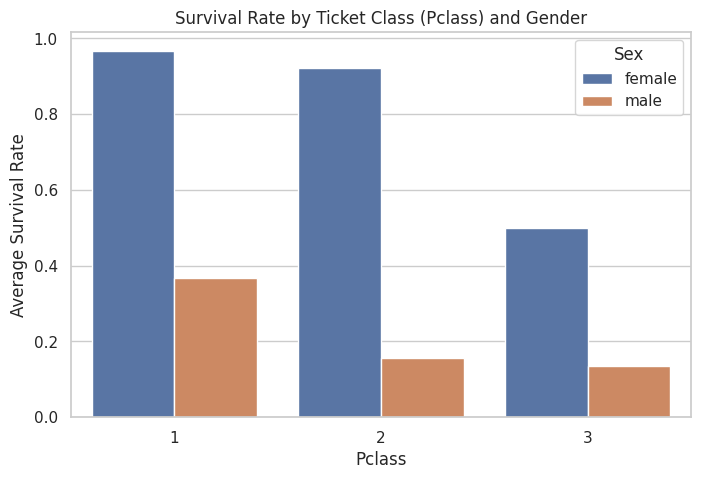

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Helper function to display section headers
def print_header(title):
    print("\n" + "="*80)
    print(f" {title} ".center(80, "="))
    print("="*80 + "\n")

# Load the Titanic dataset from a reliable public URL
print_header("Loading Titanic Dataset")
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic_df = pd.read_csv(url)
print("Dataset loaded successfully. Shape:", titanic_df.shape)
print(titanic_df.head(3))

# Fill missing values for analysis
titanic_df['Age'] = titanic_df['Age'].fillna(titanic_df['Age'].median())
titanic_df['Fare'] = titanic_df['Fare'].fillna(titanic_df['Fare'].median())

# =========================================================================
# Exercise 1: Data Scaling and Normalization
# =========================================================================
print_header("Exercise 1: Data Scaling and Normalization")

# Identify numerical columns
num_cols = ['Age', 'Fare']
print("Numerical columns selected:", num_cols)

# Apply Z-score scaling (Standardization)
scaler_std = StandardScaler()
titanic_df['Age_standardized'] = scaler_std.fit_transform(titanic_df[['Age']])

# Apply Min-Max scaling
scaler_minmax = MinMaxScaler()
titanic_df['Fare_minmax'] = scaler_minmax.fit_transform(titanic_df[['Fare']])

print("Standardized Age (head):\n", titanic_df['Age_standardized'].head(3))
print("\nMin-Max Normalized Fare (head):\n", titanic_df['Fare_minmax'].head(3))

# Analyze effect of scaling on a simple Logistic Regression model performance
# Features: Age, Fare (Using non-scaled vs scaled variants)
X_raw = titanic_df[['Age', 'Fare']]
y = titanic_df['Survived']

X_scaled = pd.DataFrame({
    'Age_std': titanic_df['Age_standardized'],
    'Fare_minmax': titanic_df['Fare_minmax']
})

# Evaluate with Raw features
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_raw, y, test_size=0.2, random_state=42)
clf_raw = LogisticRegression().fit(X_train_r, y_train_r)
raw_acc = accuracy_score(y_test_r, clf_raw.predict(X_test_r))

# Evaluate with Scaled features
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
clf_scaled = LogisticRegression().fit(X_train_s, y_train_s)
scaled_acc = accuracy_score(y_test_s, clf_scaled.predict(X_test_s))

print(f"\nModel Accuracy (Unscaled features): {raw_acc:.4f}")
print(f"Model Accuracy (Scaled features): {scaled_acc:.4f}")

# =========================================================================
# Exercise 2: Creating Composite Features
# =========================================================================
print_header("Exercise 2: Creating Composite Features")

# Create 'Family Size' (SibSp + Parch + 1 for themselves)
titanic_df['Family_Size'] = titanic_df['SibSp'] + titanic_df['Parch'] + 1

# Create 'IsAlone'
titanic_df['IsAlone'] = 0
titanic_df.loc[titanic_df['Family_Size'] == 1, 'IsAlone'] = 1

print(titanic_df[['SibSp', 'Parch', 'Family_Size', 'IsAlone']].head(5))

# Explore relationship with Survival Rate
survival_by_family = titanic_df.groupby('Family_Size')['Survived'].mean()
survival_by_alone = titanic_df.groupby('IsAlone')['Survived'].mean()

print("\nSurvival Rate by Family Size:\n", survival_by_family)
print("\nSurvival Rate by Alone Status:\n", survival_by_alone)

# =========================================================================
# Exercise 3: Data Normalization on the Titanic Dataset
# =========================================================================
print_header("Exercise 3: Data Normalization comparison using Histograms")

# Apply both normalization techniques to both columns
titanic_df['Age_minmax'] = scaler_minmax.fit_transform(titanic_df[['Age']])
titanic_df['Fare_standardized'] = scaler_std.fit_transform(titanic_df[['Fare']])

# Compare distributions before and after
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Age plots
sns.histplot(titanic_df['Age'], kde=True, ax=axes[0, 0], color='blue').set(title='Original Age')
sns.histplot(titanic_df['Age_minmax'], kde=True, ax=axes[0, 1], color='green').set(title='Min-Max Scaled Age')
sns.histplot(titanic_df['Age_standardized'], kde=True, ax=axes[0, 2], color='red').set(title='Z-score Standardized Age')

# Fare plots
sns.histplot(titanic_df['Fare'], kde=True, ax=axes[1, 0], color='blue').set(title='Original Fare')
sns.histplot(titanic_df['Fare_minmax'], kde=True, ax=axes[1, 1], color='green').set(title='Min-Max Scaled Fare')
sns.histplot(titanic_df['Fare_standardized'], kde=True, ax=axes[1, 2], color='red').set(title='Z-score Standardized Fare')

plt.tight_layout()
plt.show()

# =========================================================================
# Exercise 4: Data Reduction and Aggregation
# =========================================================================
print_header("Exercise 4: PCA and Aggregation on Titanic")

# Select continuous numerical columns for PCA
pca_features = ['Age_standardized', 'Fare_standardized', 'Family_Size']
x_pca = titanic_df[pca_features]

pca = PCA(n_components=2)
pca_result = pca.fit_transform(x_pca)
titanic_df['PCA1'] = pca_result[:, 0]
titanic_df['PCA2'] = pca_result[:, 1]

print(f"Explained variance ratio of 2 main components: {pca.explained_variance_ratio_}")

# Aggregate data by categorical columns (Pclass and Sex)
agg_df = titanic_df.groupby(['Pclass', 'Sex']).agg({
    'Survived': 'mean',
    'Age': 'mean',
    'Fare': 'mean',
    'Family_Size': 'mean'
}).reset_index()

print("\nAggregated Summary Stats by Pclass and Sex:\n", agg_df)

# Visualizing the aggregated survival data
plt.figure(figsize=(8, 5))
sns.barplot(x='Pclass', y='Survived', hue='Sex', data=agg_df)
plt.title('Survival Rate by Ticket Class (Pclass) and Gender')
plt.ylabel('Average Survival Rate')
plt.show()
